In [88]:
import numpy as np
import pandas as pd 
from matplotlib import pyplot as plt

In [89]:
training = np.loadtxt('trainingI.dat')
validation = np.loadtxt('validationI.dat')
ranges = np.loadtxt('rangesII.dat')
checkpoints = np.loadtxt('checkpointsII.dat')
anchors = np.loadtxt('anchorsII.dat')

In [90]:
def legendre(x, n):
    P = np.zeros(n)

    P[0] = 1
    P[1] = x

    for k in range(1, n-1):
        P[k+1] = ((2*k+1)*x*P[k] - k*P[k-1])/(k+1)

    return P

In [91]:
x = training[:, 0]
b = training[:, 1]

n = 8
m = 60

A = np.zeros((m, n))

for i in range(m):
    A[i, :] = legendre(x[i], n)

In [92]:
theta_ls = np.linalg.inv(A.T @ A) @ A.T @ b


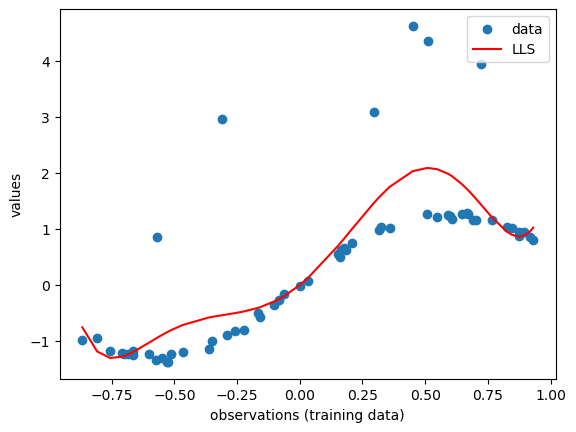

In [93]:

plt.scatter(x, b, label = 'data')
plt.plot(x, A@theta_ls, color = 'red' ,label = 'LLS')
plt.xlabel('observations (training data)')
plt.ylabel('values')
plt.legend()

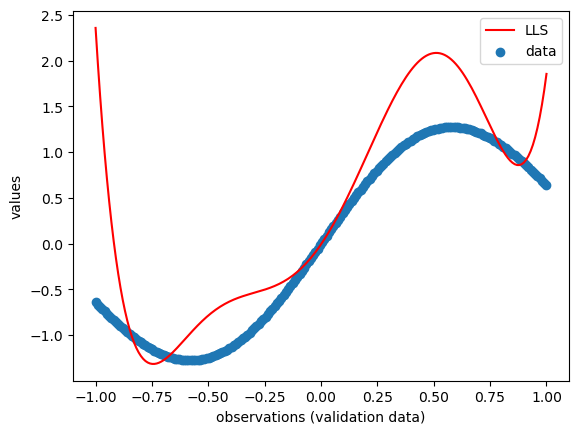

In [94]:
x2, b2 = validation[:, 0], validation[:, 1]
A2 = np.zeros((200,8))
for i in range(200):
    A2[i, :] = legendre(x2[i], n)
    
theta_2 = np.linalg.inv(A2.T @ A2) @ A2.T @ b2
plt.plot(x2, A2@theta_ls, color = 'red', label = 'LLS')
plt.scatter(x2, b2, label = 'data')
plt.xlabel('observations (validation data)')
plt.ylabel('values')
plt.legend()


In [95]:
validation_error = 0
V = A2 @ theta_ls
for i in range(200):
    validation_error += (abs(V[i] - b2[i]))**2

validation_error = validation_error / 200
validation_error

np.float64(0.3457172773966428)

In [96]:
residuals = A2 @ theta_ls - b2
residuals_outliers = A @ theta_ls - b

Text(0.5, 1.0, 'residuals for training data')

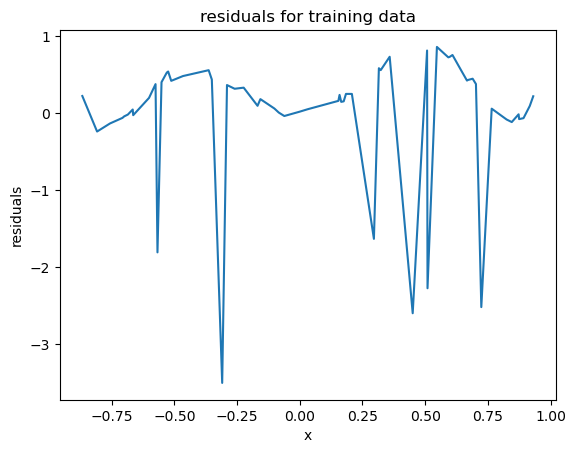

In [97]:
plt.plot(x , residuals_outliers)
plt.xlabel('x')
plt.ylabel('residuals')
plt.title('residuals for training data')

Text(0.5, 1.0, 'residuals for validation data')

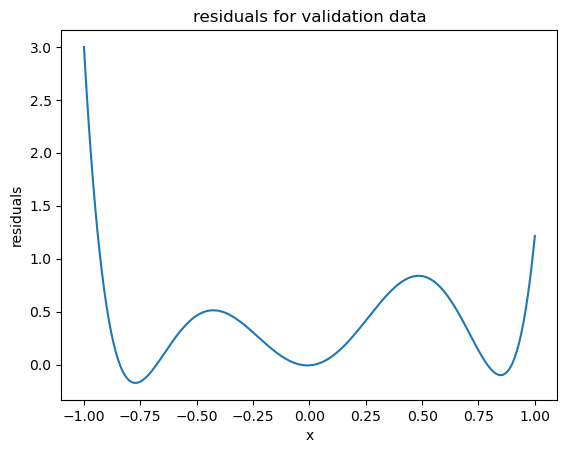

In [98]:
plt.plot(x2, residuals)
plt.xlabel('x')
plt.ylabel('residuals')
plt.title('residuals for validation data')

In [99]:
np.linalg.cond(A2.T@A2)

np.float64(14.210429548748612)

In [100]:
def polynomial(x, n):
    P = np.zeros(n)
    P[0] = 1
    for i in range(1, n):
        P[i] = x**i
    return P
    
        
        
        

In [101]:
A3 = np.zeros((200, 8))
for i in range(200):
    A3[i : ,] = polynomial(x2[i], n)

np.linalg.cond(A3.T@A3)

np.float64(52902.529947814524)

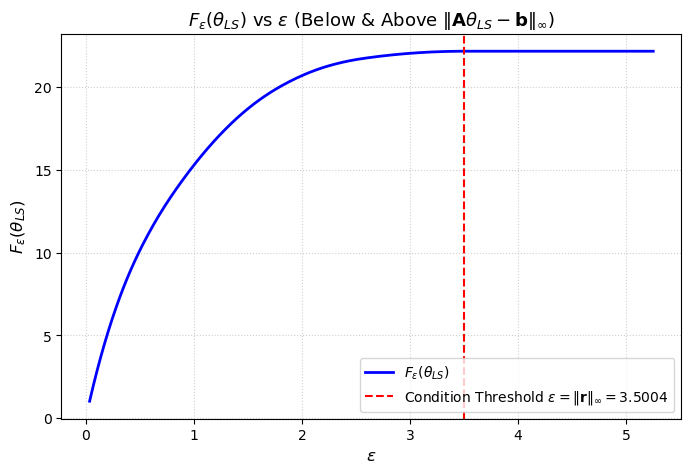

In [102]:

# 1. Define the element-wise Huber loss
def huber_loss(t, eps):
    return np.where(np.abs(t) <= eps, 0.5 * t**2, eps * (np.abs(t) - 0.5 * eps))

# 2. Residuals & max norm condition
res = A @ theta_ls - b
max_res = np.max(np.abs(res))  # ||A*theta_LS - b||_infty

# 3. Create a range of epsilon values (from slightly above 0 to max_res * 1.5)
eps_values = np.linspace(0.01 * max_res, 1.5 * max_res, 300)
f_values = []

# 4. Compute F_eps(theta_LS) for each epsilon
for eps in eps_values:
    # Sum Huber loss across all residual elements
    F_eps = np.sum(huber_loss(res, eps))
    f_values.append(F_eps)

# 5. Distance from the condition: (max_res - epsilon)
# Positive distance = epsilon is BELOW the condition (epsilon < max_res)
# Negative distance = epsilon is ABOVE the condition (epsilon > max_res)
distance_from_condition = max_res - eps_values

# --- Plotting ---
plt.figure(figsize=(8, 5))
plt.plot(eps_values, f_values, label=r'$F_\epsilon(\theta_{LS})$', color='blue', linewidth=2)

# Vertical line at the threshold epsilon = ||A*theta_LS - b||_infty
plt.axvline(x=max_res, color='red', linestyle='--', 
            label=rf'Condition Threshold $\epsilon = \|\mathbf{{r}}\|_{{\infty}} = {max_res:.4f}$')

plt.xlabel(r'$\epsilon$', fontsize=12)
plt.ylabel(r'$F_\epsilon(\theta_{LS})$', fontsize=12)
plt.title(r'$F_\epsilon(\theta_{LS})$ vs $\epsilon$ (Below & Above $\|\mathbf{A}\theta_{LS} - \mathbf{b}\|_\infty$)', fontsize=13)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()



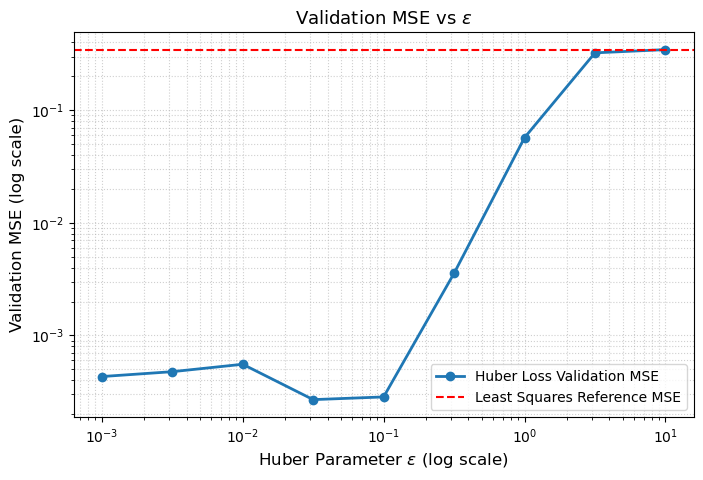

[20699, 13805, 6208, 3693, 2727, 3165, 3633, 3852, 3854]


In [103]:
import numpy as np
import matplotlib.pyplot as plt

def gradient_descent_huber(A, b, eps, stepsize, tol=1e-6, max_iter=500000):
    m, n = A.shape
    theta = np.zeros(n)
    
    for k in range(max_iter):
        residual = A @ theta - b
        # Huber gradient: A^T * clip(A*theta - b, -eps, eps)
        grad = A.T @ np.clip(residual, -eps, eps)
        
        # Stopping criterion based on gradient norm
        if np.linalg.norm(grad) <= tol:
            return theta, k + 1
        
        # Standard gradient descent update with constant stepsize t = 1 / sigma_max(A)^2
        theta = theta - stepsize * grad
        
    return theta, max_iter

# --- Run for eps = 10^-3, 10^-2.5, ..., 10^1 ---
eps_powers = np.arange(-3, 1.5, 0.5)
eps_values = 10**eps_powers

# Constant stepsize specified in the assignment
sigma_max = np.linalg.norm(A, 2)
t_step = 1.0 / (sigma_max**2)

val_mses = []
iterations = []

# Reference Least Squares Validation MSE
theta_ls = np.linalg.lstsq(A, b, rcond=None)[0]
ls_val_mse = np.mean((A2 @ theta_ls - b2)**2)
for ep in eps_values:
    theta_opt, num_iter = gradient_descent_huber(A, b, ep, stepsize=t_step, tol=1e-6)
    iterations.append(num_iter)
    
    # Calculate Validation MSE on clean validation dataset
    res_val = A2 @ theta_opt - b2
    mse_val = np.mean(res_val**2)
    val_mses.append(mse_val)
    


# --- Plot Validation MSE vs Epsilon ---
plt.figure(figsize=(8, 5))
plt.loglog(eps_values, val_mses, 'o-', label='Huber Loss Validation MSE', color='C0', linewidth=2)
plt.axhline(y=ls_val_mse, color='red', linestyle='--', label='Least Squares Reference MSE', linewidth=1.5)

plt.xlabel(r'Huber Parameter $\epsilon$ (log scale)', fontsize=12)
plt.ylabel('Validation MSE (log scale)', fontsize=12)
plt.title(r'Validation MSE vs $\epsilon$', fontsize=13)
plt.legend()
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.show()
print(iterations)

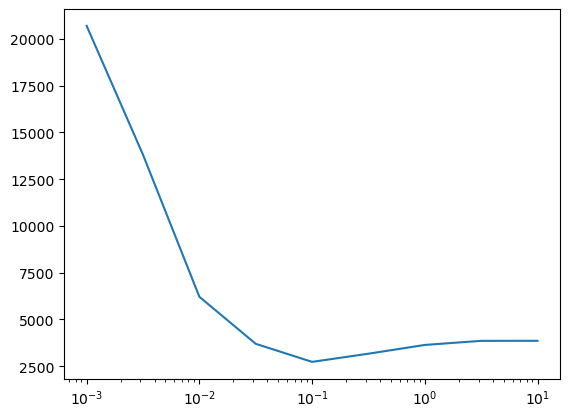

In [104]:
plt.semilogx(eps_values, iterations)

Best Epsilon: 3.1623e-02 with Validation MSE: 0.000269


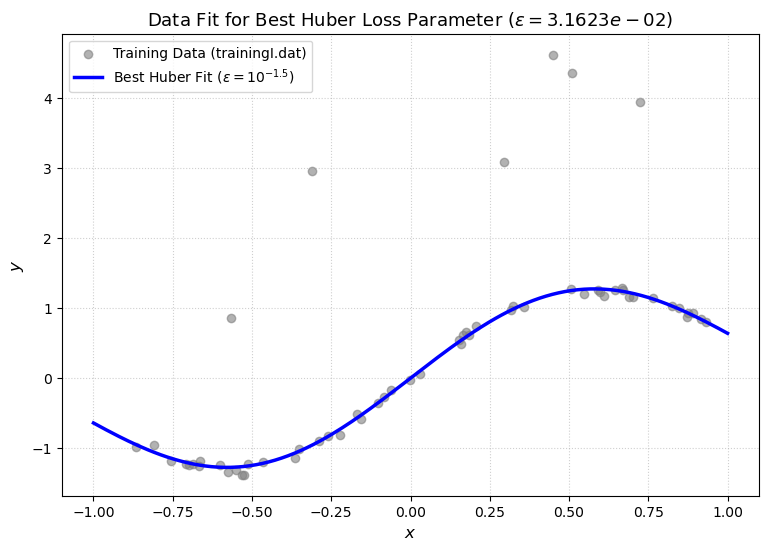

In [105]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Identify the best epsilon (lowest validation MSE)
best_idx = np.argmin(val_mses)
best_eps = eps_values[best_idx]
print(f"Best Epsilon: {best_eps:.4e} with Validation MSE: {val_mses[best_idx]:.6f}")

# 2. Re-run or extract the optimal theta for best_eps
theta_best, _ = gradient_descent_huber(A2, b2, best_eps, stepsize=t_step, tol=1e-5)

# 3. Compute fitted values for training data
# For a smooth curve plot across the input range x:

# Build matrix A_dense for plotting smooth curve
# Assuming degree n (e.g., Legendre basis or Monomial basis)
# Example for Legendre basis:

# Compute predictions
y_huber_fit = A2 @ theta_best
y_ls_fit = A @ theta_ls

# --- Plotting the Fit ---
plt.figure(figsize=(9, 6))

# Plot raw training points
plt.scatter(x, b, color='gray', alpha=0.6, label='Training Data (trainingI.dat)')

# Plot Huber fit for best epsilon
plt.plot(x2, y_huber_fit, color='blue', linewidth=2.5, 
         label=rf'Best Huber Fit ($\epsilon = 10^{{{eps_powers[best_idx]:.1f}}}$)')

# Plot Least Squares fit for comparison
# plt.plot(x, y_ls_fit, color='red', linestyle='--', linewidth=2, 
#          label='Least Squares Fit ($\ell_2$)')

plt.xlabel('$x$', fontsize=12)
plt.ylabel('$y$', fontsize=12)
plt.title(rf'Data Fit for Best Huber Loss Parameter ($\epsilon = {best_eps:.4e}$)', fontsize=13)
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

In [106]:
outliers = []
x_rest = [i for i in x if i < -0.5]
for i in range(len(x_rest)):
    if b[i] > 0:
        outliers.append(i+1)
for i,x_vals in enumerate(x):
    if b[i] > 2:
        outliers.append(i+1)
outliers

    
        

[11, 19, 36, 40, 42, 52]

In [107]:


r_t = ranges[0]  

def compute_hessian_g1(p, anchors, r_t):
    hess = np.zeros((2, 2))
    

    for i in range(3):
        diff = p - anchors[i]  
        dist_sq = np.sum(diff**2)  
        outer_term = 2 * np.outer(diff, diff)
        identity_term = (dist_sq - r_t[i]**2) * np.eye(2)
        hess += outer_term + identity_term
        
    return hess


for idx in range(3):
    p_anchor = anchors[idx]
    H = compute_hessian_g1(p_anchor, anchors, r_t)
    
    print(f"--- Hessian at Anchor s_{idx+1} ({p_anchor}) ---")
    print(H)
    


--- Hessian at Anchor s_1 ([0. 0.]) ---
[[263.69281078   4.        ]
 [  4.          14.01281078]]
--- Hessian at Anchor s_2 ([5.  0.4]) ---
[[ 38.85281078   0.        ]
 [  0.         -60.50718922]]
--- Hessian at Anchor s_3 ([10.  0.]) ---
[[263.69281078  -4.        ]
 [ -4.          14.01281078]]


eps                                                                                                  |I| (Inliers) lambda_min(A_I^T A_I)    
--------------------------------------------------
1.0e-02    18              9.483307e-02             
1.0e-01    52              1.839245e-01             
1.0e+00    54              1.911875e-01             


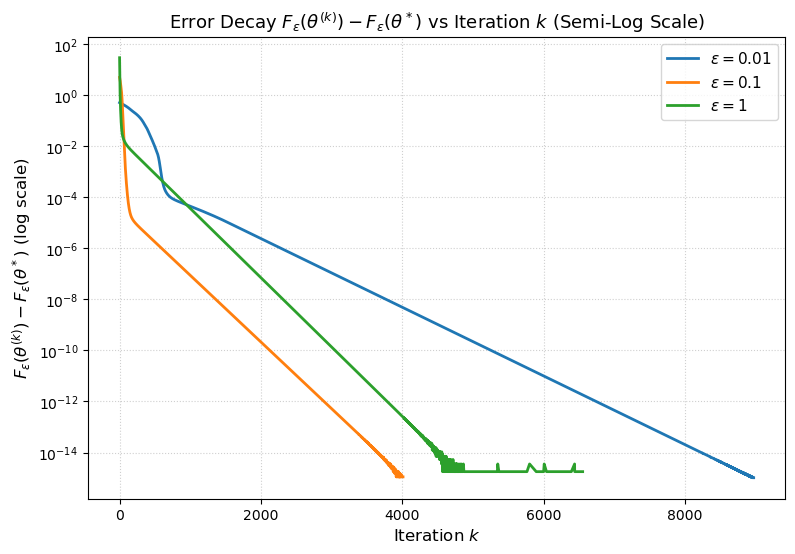

In [108]:

# 1. Huber Loss function evaluation
def huber_loss_total(A, b, theta, eps):
    r = A @ theta - b
    abs_r = np.abs(r)
    quad_mask = abs_r <= eps
    loss = np.where(quad_mask, 0.5 * r**2, eps * (abs_r - 0.5 * eps))
    return np.sum(loss)

# 2. Gradient Descent saving cost history
def gd_huber_history(A, b, eps, stepsize, tol=1e-8, max_iter=200000):
    m, n = A.shape
    theta = np.zeros(n)
    cost_history = []
    
    for k in range(max_iter):
        r = A @ theta - b
        cost_history.append(huber_loss_total(A, b, theta, eps))
        
        grad = A.T @ np.clip(r, -eps, eps)
        if np.linalg.norm(grad) <= tol:
            break
            
        theta = theta - stepsize * grad
        
    return theta, np.array(cost_history)

# Step size t = 1 / sigma_max(A)^2
sigma_max = np.linalg.norm(A, 2)
t_step = 1.0 / (sigma_max**2)

eps_target = [10**-2, 10**-1, 1]

plt.figure(figsize=(9, 6))

print(f"{'eps':<100} {'|I| (Inliers)':<1} {'lambda_min(A_I^T A_I)':<25}")
print("-" * 50)

for ep in eps_target:
    # Run to high precision to get optimal theta* and history
    theta_opt, history = gd_huber_history(A, b, ep, stepsize=t_step, tol=1e-10, max_iter=250000)
    
    F_star = history[-1]  # F_eps(theta*)
    
    # Compute active set I = { i : |r_i| < eps }
    r_opt = A @ theta_opt - b
    I_mask = np.abs(r_opt) < ep
    I_size = np.sum(I_mask)
    
    # Submatrix A_I formed by rows indexed by I
    A_I = A[I_mask, :]
    hessian_I = A_I.T @ A_I
    lambda_min = np.min(np.linalg.eigvalsh(hessian_I))
    
    print(f"{ep:<10.1e} {I_size:<15} {lambda_min:<25.6e}")
    
    # Compute F_eps(theta^k) - F_eps(theta*)
    error_decay = history - F_star
    
    # Filter out tiny or zero/negative differences for log plotting
    valid_k = error_decay > 1e-15
    k_axis = np.arange(len(history))[valid_k]
    decay_values = error_decay[valid_k]
    
    # Plot on semi-log scale (y-axis log, x-axis linear)
    plt.semilogy(k_axis, decay_values, label=rf'$\epsilon = {ep}$', linewidth=2)

plt.xlabel('Iteration $k$', fontsize=12)
plt.ylabel(r'$F_\epsilon(\theta^{(k)}) - F_\epsilon(\theta^*)$ (log scale)', fontsize=12)
plt.title(r'Error Decay $F_\epsilon(\theta^{(k)}) - F_\epsilon(\theta^*)$ vs Iteration $k$ (Semi-Log Scale)', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.show()

In [109]:
def gradient_descent_gt(t_idx, p_init, anchors, ranges, stepsize=1e-3, tol=1e-6, max_iter=10000):
    p = p_init.copy()
    r_t = ranges[t_idx]  # Radii r_{t,1}, r_{t,2}, r_{t,3} at time t
    
    for k in range(max_iter):
        grad = np.zeros(2)
        for i in range(3):
            diff = p - anchors[i]
            dist_sq = np.sum(diff**2)
            grad += (dist_sq - r_t[i]**2) * diff
            
        # 2. Check Stopping Criterion (Gradient Norm)
        if np.linalg.norm(grad) <= tol:
            break
            
        # 3. Gradient update step with stepsize 10^-3
        p = p - stepsize * grad
        
    return p

In [110]:
# --- 1. Compute Matrix C (Constant across all time t) ---
# s1, s2, s3 are rows of anchors array (shape 3x2)
# C has rows 2*(s_2 - s_1)^T and 2*(s_3 - s_1)^T
C = np.zeros((2, 2))
C[0, :] = 2 * (anchors[1] - anchors[0])
C[1, :] = 2 * (anchors[2] - anchors[0])

# Pre-compute anchor squared norms
norm_s1_sq = np.sum(anchors[0]**2)
norm_s2_sq = np.sum(anchors[1]**2)
norm_s3_sq = np.sum(anchors[2]**2)

lls = []
descents = []

# --- 2. Loop over each timestamp t = 0 to 59 ---
for t in range(60):
    r1, r2, r3 = ranges[t]  # measured distances at time t
    
    # Construct vector d_t
    d_t = np.array([
        r1**2 - r2**2 + norm_s2_sq - norm_s1_sq,
        r1**2 - r3**2 + norm_s3_sq - norm_s1_sq
    ])
    
    # Solve linearised least squares estimate: p_LLS = (C^T C)^(-1) C^T d_t
    # Since C is 2x2 non-singular, p_LLS = C^(-1) d_t
    p_lls = np.linalg.inv(C.T @ C) @ C.T @ d_t
    
    # Run gradient descent initialized at p_LLS
    p_descent = gradient_descent_gt(t, p_lls, anchors, ranges, stepsize=1e-3, tol=1e-6, max_iter=10000)
    
    lls.append(p_lls)
    descents.append(p_descent)

# Convert to (60, 2) arrays
lls_arr = np.array(lls)
descents_arr = np.array(descents)

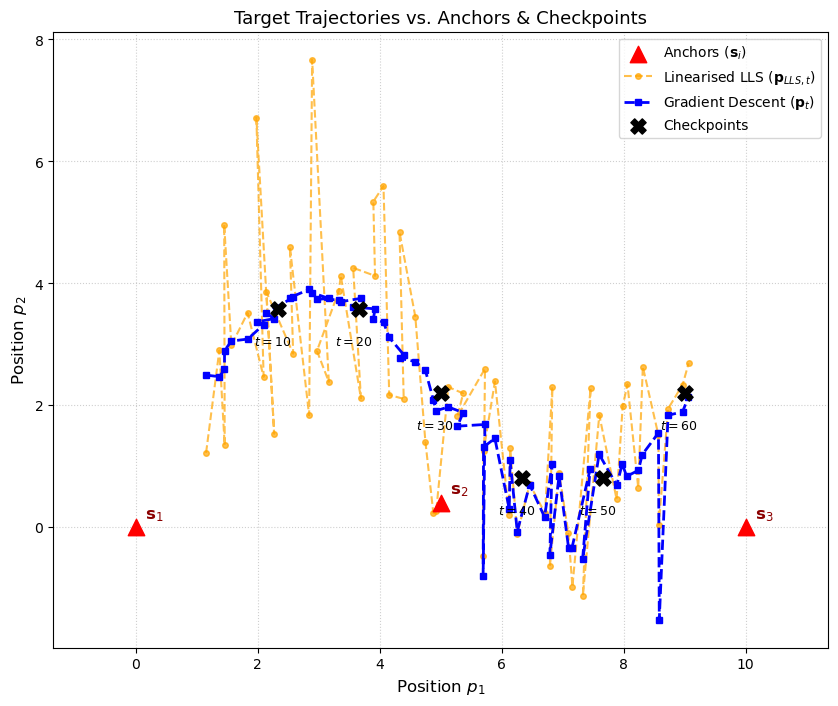

In [117]:
lls_arr = np.array(lls)           # shape (60, 2)
descents_arr = np.array(descents) # shape (60, 2)

# 2. Extract validation checkpoints
check_t = checkpoints[:, 0].astype(int)
check_pos = checkpoints[:, 1:3]

plt.figure(figsize=(10, 8))

# --- Plot 3 Anchors ---
plt.scatter(anchors[:, 0], anchors[:, 1], color='red', marker='^', s=140, zorder=5, label=r'Anchors ($\mathbf{s}_i$)')
for i, (ax_i, ay_i) in enumerate(anchors):
    plt.text(ax_i + 0.15, ay_i + 0.15, f'$\mathbf{{s}}_{{{i+1}}}$', fontsize=12, color='darkred', weight='bold')

# --- Plot Trajectories (p1 vs p2) ---
# LLS Trajectory (Orange dashed)
plt.plot(lls_arr[:, 0], lls_arr[:, 1], 'o--', color='orange', alpha=0.7, linewidth=1.5, markersize=4, label=r'Linearised LLS ($\mathbf{p}_{LLS,t}$)')

# Gradient Descent Trajectory (Blue solid)
plt.plot(descents_arr[:, 0], descents_arr[:, 1], 's--', color='blue', linewidth=2, markersize=5, label=r'Gradient Descent ($\mathbf{p}_t$)')

# --- Plot Ground-Truth Checkpoints ---
plt.scatter(check_pos[:, 0], check_pos[:, 1], color='black', marker='X', s=120, zorder=6, label=r'Checkpoints')
for t_val, (cx, cy) in zip(check_t, check_pos):
    plt.text(cx - 0.4, cy - 0.6, f'$t={t_val}$', fontsize=9, color='black', weight='bold')

plt.xlabel('Position $p_1$', fontsize=12)
plt.ylabel('Position $p_2$', fontsize=12)
plt.title(r'Target Trajectories vs. Anchors & Checkpoints', fontsize=13)
plt.legend(loc='upper right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.axis('equal')  # Ensures 1:1 spatial aspect ratio so path shapes are unwarped
plt.show()

In [112]:
# Extract the 6 checkpoint positions (shape 6x2)
check_t = checkpoints[:, 0].astype(int)  # [10, 20, 30, 40, 50, 60]
check_pos = checkpoints[:, 1:3]           # Ground truth (p1, p2)

# Convert 1-indexed time t to 0-indexed array indices (t - 1)
check_indices = check_t - 1

# Extract estimated positions at the 6 checkpoint times
lls_check = lls_arr[check_indices]
gd_check = descents_arr[check_indices]

# Compute RMS error Eck
E_ck_lls = np.sqrt(np.mean(np.sum((lls_check - check_pos)**2, axis=1)))
E_ck_gd  = np.sqrt(np.mean(np.sum((gd_check - check_pos)**2, axis=1)))

print(f"E_ck (Linearised LLS): {E_ck_lls:.4f}")
print(f"E_ck (Gradient Descent): {E_ck_gd:.4f}")

E_ck (Linearised LLS): 1.0387
E_ck (Gradient Descent): 0.4254


In [113]:
cond_C_sq = np.linalg.cond(C.T @ C)
print(f"Condition Number kappa(C^T C): {cond_C_sq:.4e}")

Condition Number kappa(C^T C): 9.7706e+02


lambda = 0.1      | E_ck = 0.288998
lambda = 1.0      | E_ck = 0.208625
lambda = 10.0     | E_ck = 0.146310
lambda = 100.0    | E_ck = 0.225245
lambda = 1000.0   | E_ck = 0.469529


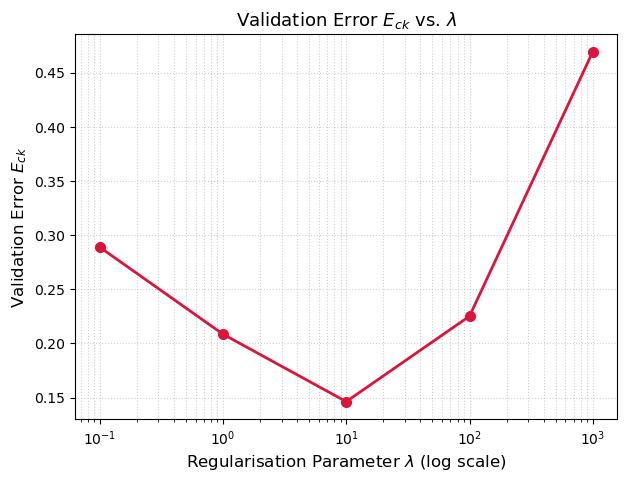

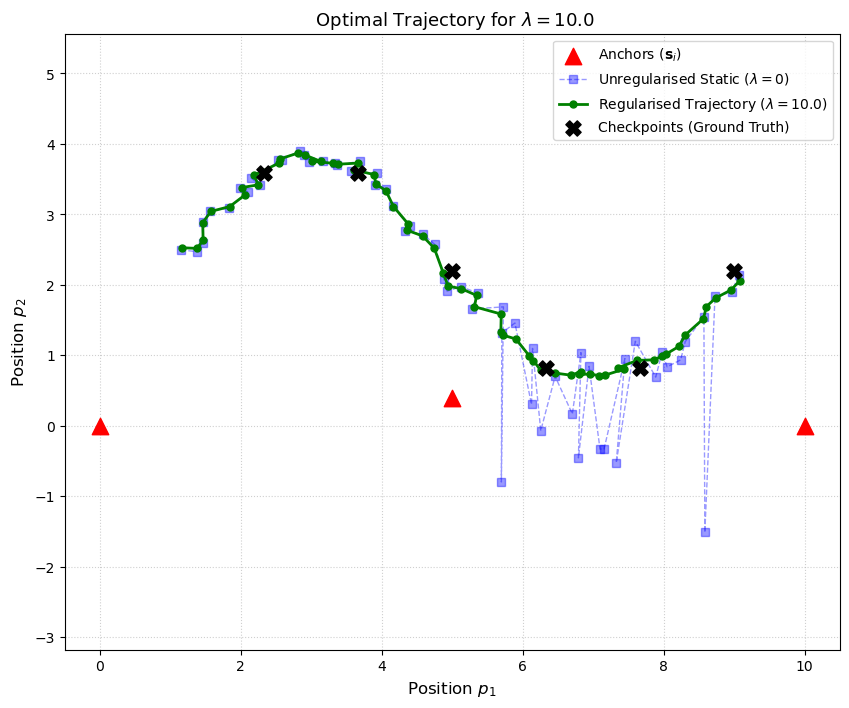

In [114]:
T = 60
D = np.eye(T - 1, T, k=0) * (-1.0) + np.eye(T - 1, T, k=1)
DTD = D.T @ D  # Matrix product D^T * D of shape (T, T)

# --- B. Define Gradient of G_lambda(P) ---
def compute_grad_G_lambda(P, anchors, ranges, DTD, lam):
    """
    Computes the matrix gradient nabla G_lambda(P) of shape (T, 2).
    """
    T_steps, _ = P.shape
    G_static = np.zeros((T_steps, 2))
    
    # Static gradient part for each time step t
    for t in range(T_steps):
        r_t = ranges[t]
        p_t = P[t]
        grad_t = np.zeros(2)
        for i in range(3):
            diff = p_t - anchors[i]
            dist_sq = np.sum(diff**2)
            grad_t += (dist_sq - r_t[i]**2) * diff
        G_static[t] = grad_t
        
    # Regularisation gradient part: lambda * D^T * D * P
    G_reg = lam * (DTD @ P)
    
    return G_static + G_reg

# --- C. Gradient Descent Solver for G_lambda ---
def gd_G_lambda(P_init, anchors, ranges, DTD, lam, tol=1e-6, max_iter=20000):
    P = P_init.copy()
    stepsize = 1.0 / (1000.0 + 4.0 * lam)  # Stepsize specified in II.d)(ii)
    
    for k in range(max_iter):
        grad_P = compute_grad_G_lambda(P, anchors, ranges, DTD, lam)
        
        # Stopping criterion based on Frobenius norm of gradient
        if np.linalg.norm(grad_P, 'fro') <= tol:
            break
            
        P = P - stepsize * grad_P
        
    return P

# --- D. Run for lambda in {10^-1, 1, 10, 10^2, 10^3} ---
lambda_values = [0.1, 1.0, 10.0, 100.0, 1000.0]

# Initial point: static estimates P_static (shape 60x2) computed in Part II.c
# (descents_arr or lls_arr)
P_init_static = descents_arr.copy()

check_t = checkpoints[:, 0].astype(int)
check_pos = checkpoints[:, 1:3]
check_indices = check_t - 1  # 0-indexed indices for checkpoints

E_ck_list = []
trajectories = {}

for lam in lambda_values:
    P_opt = gd_G_lambda(P_init_static, anchors, ranges, DTD, lam)
    trajectories[lam] = P_opt
    
    # Compute Eck
    P_check = P_opt[check_indices]
    E_ck = np.sqrt(np.mean(np.sum((P_check - check_pos)**2, axis=1)))
    E_ck_list.append(E_ck)
    print(f"lambda = {lam:<8.1f} | E_ck = {E_ck:.6f}")

# --- E. Plot 1: E_ck vs Lambda (Semi-Log Scale) ---
plt.figure(figsize=(7, 5))
plt.semilogx(lambda_values, E_ck_list, 'o-', color='crimson', linewidth=2, markersize=7)
plt.xlabel(r'Regularisation Parameter $\lambda$ (log scale)', fontsize=12)
plt.ylabel(r'Validation Error $E_{ck}$', fontsize=12)
plt.title(r'Validation Error $E_{ck}$ vs. $\lambda$', fontsize=13)
plt.grid(True, which="both", linestyle=":", alpha=0.6)
plt.show()

# --- F. Plot 2: Selected Trajectory for Best Lambda ---
best_idx = np.argmin(E_ck_list)
best_lambda = lambda_values[best_idx]
best_P = trajectories[best_lambda]

plt.figure(figsize=(10, 8))
plt.scatter(anchors[:, 0], anchors[:, 1], color='red', marker='^', s=140, zorder=5, label=r'Anchors ($\mathbf{s}_i$)')
plt.plot(descents_arr[:, 0], descents_arr[:, 1], 's--', color='blue', alpha=0.4, linewidth=1, label=r'Unregularised Static ($\lambda=0$)')
plt.plot(best_P[:, 0], best_P[:, 1], 'o-', color='green', linewidth=2, markersize=5, label=rf'Regularised Trajectory ($\lambda={best_lambda}$)')
plt.scatter(check_pos[:, 0], check_pos[:, 1], color='black', marker='X', s=120, zorder=6, label=r'Checkpoints (Ground Truth)')

plt.xlabel('Position $p_1$', fontsize=12)
plt.ylabel('Position $p_2$', fontsize=12)
plt.title(rf' Optimal Trajectory for $\lambda = {best_lambda}$', fontsize=13)
plt.legend(loc='upper right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.axis('equal')
plt.show()

In [115]:
lls_arr2 = lls_arr
for i in range(60):
    lls_arr2[i][1] = lls_arr2[i][1] * -1
lls_arr2

array([[ 1.15364696, -1.22060223],
       [ 1.37102   , -2.90073461],
       [ 1.45888133, -1.34542888],
       [ 1.45095462, -4.96430484],
       [ 1.5681301 , -2.98540651],
       [ 1.83461771, -3.51692559],
       [ 2.09746386, -2.46718901],
       [ 1.97850766, -6.71808682],
       [ 2.27018671, -1.53427988],
       [ 2.14355757, -3.86035653],
       [ 2.58161574, -2.84776307],
       [ 2.52858786, -4.59274788],
       [ 2.84361893, -1.83744852],
       [ 2.89254696, -7.66759113],
       [ 3.16641632, -2.38614044],
       [ 2.97178194, -2.89341591],
       [ 3.32986265, -3.87346849],
       [ 3.36274205, -4.12705012],
       [ 3.69275105, -2.11413193],
       [ 3.56546703, -4.25509106],
       [ 3.92422923, -4.1239239 ],
       [ 3.89612481, -5.3421165 ],
       [ 4.06277843, -5.5972877 ],
       [ 4.15683777, -2.17191946],
       [ 4.39437927, -2.10602886],
       [ 4.32545907, -4.84112108],
       [ 4.58475742, -3.4541273 ],
       [ 4.74947721, -1.40758882],
       [ 4.88079054,

PART II.d)(iii) COMPARISON RESULTS (lambda = 10.0)
Original Optimised P*    | G_lambda = 28.300035 | E_ck = 0.146310
Mirror-Image Optimised   | G_lambda = 173.425322 | E_ck = 4.628364


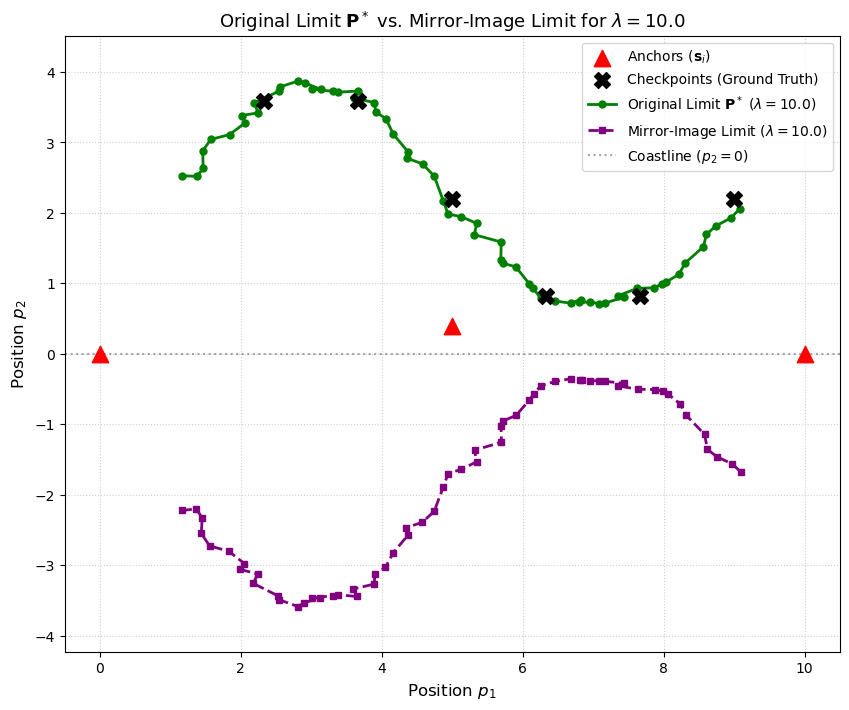

In [118]:
lam = 10.0
stepsize = 1.0 / (1000.0 + 4.0 * lam)

# 2. Get the optimal trajectory P* from Part II.d)(ii)
# P_star shape is (T, 2), where column 0 is p_1 and column 1 is p_2
P_star = trajectories[lam].copy()

# 3. Create the Mirror-Image Initialisation: P_mirror = [p_1*, -p_2*]
P_mirror_init = P_star.copy()
P_mirror_init[:, 1] = -P_mirror_init[:, 1]  # Flip the sign of the p2 coordinate

# 4. Define Helper Functions for Objectives G_lambda and g_t
def compute_G_lambda(P, anchors, ranges, DTD, lam):
    T_steps, _ = P.shape
    total_g_t = 0.0
    for t in range(T_steps):
        r_t = ranges[t]
        p_t = P[t]
        for i in range(3):
            diff = p_t - anchors[i]
            dist_sq = np.sum(diff**2)
            total_g_t += 0.25 * (dist_sq - r_t[i]**2)**2
            
    # Regularisation cost: (lambda / 2) * ||D P||_F^2 = (lambda / 2) * tr(P^T D^T D P)
    reg_cost = 0.5 * lam * np.trace(P.T @ DTD @ P)
    return total_g_t + reg_cost

# 5. Run Gradient Descent starting from P_mirror_init
P_mirror_opt = gd_G_lambda(P_mirror_init, anchors, ranges, DTD, lam, tol=1e-6, max_iter=30000)

# 6. Compute Objectives G_lambda for both limits
G_val_orig = compute_G_lambda(P_star, anchors, ranges, DTD, lam)
G_val_mirr = compute_G_lambda(P_mirror_opt, anchors, ranges, DTD, lam)

# 7. Compute Validation RMS Error (E_ck) for both limits
check_t = checkpoints[:, 0].astype(int)
check_pos = checkpoints[:, 1:3]
check_indices = check_t - 1

check_orig = P_star[check_indices]
check_mirr = P_mirror_opt[check_indices]

E_ck_orig = np.sqrt(np.mean(np.sum((check_orig - check_pos)**2, axis=1)))
E_ck_mirr = np.sqrt(np.mean(np.sum((check_mirr - check_pos)**2, axis=1)))

# --- Display Comparison Metrics ---
print("=" * 60)
print(f"PART II.d)(iii) COMPARISON RESULTS (lambda = {lam})")
print("=" * 60)
print(f"Original Optimised P*    | G_lambda = {G_val_orig:.6f} | E_ck = {E_ck_orig:.6f}")
print(f"Mirror-Image Optimised   | G_lambda = {G_val_mirr:.6f} | E_ck = {E_ck_mirr:.6f}")
print("=" * 60)

# --- 8. Plot Trajectories ---
plt.figure(figsize=(10, 8))

# Anchors & Checkpoints
plt.scatter(anchors[:, 0], anchors[:, 1], color='red', marker='^', s=140, zorder=5, label=r'Anchors ($\mathbf{s}_i$)')
plt.scatter(check_pos[:, 0], check_pos[:, 1], color='black', marker='X', s=130, zorder=6, label=r'Checkpoints (Ground Truth)')

# Original vs Mirror Trajectories
plt.plot(P_star[:, 0], P_star[:, 1], 'o-', color='green', linewidth=2, markersize=5, label=rf'Original Limit $\mathbf{{P}}^*$ ($\lambda={lam}$)')
plt.plot(P_mirror_opt[:, 0], P_mirror_opt[:, 1], 's--', color='purple', linewidth=2, markersize=5, label=rf'Mirror-Image Limit ($\lambda={lam}$)')

# Reference coastline (y = 0 line near anchors)
plt.axhline(0, color='gray', linestyle=':', alpha=0.7, label='Coastline ($p_2 = 0$)')

plt.xlabel('Position $p_1$', fontsize=12)
plt.ylabel('Position $p_2$', fontsize=12)
plt.title(rf'Original Limit $\mathbf{{P}}^*$ vs. Mirror-Image Limit for $\lambda = {lam}$', fontsize=13)
plt.legend(loc='upper right', fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.axis('equal')
plt.show()